# 02 — Exploratory Data Analysis
**PRC-OpenSky Data Challenge 2026** · Team: thoughtful-glove

EDA on training (12 monthly parquets, ~4.17M movements) and ranking datasets.
Target: `TAXITIME_SEC_mvt` for PHASE=DEP rows across 10 European airports, full year 2025.

**Analysis areas:**
1. Target distribution per airport
2. Missingness by column × phase × dataset
3. Join quality (movement ↔ flight)
4. Ranking availability audit (drives leakage-safe feature whitelist)
5. Basic relationships (hour-of-day, runway, aircraft type, congestion)
6. Summary

No model training in this session.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.max_open_warning"] = 0

ROOT = Path.cwd().parent.parent          # project root from src/notebooks/
RAW  = ROOT / "data" / "raw"
FIGS = ROOT / "assets" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

AIRPORTS = ["EDDF","EDDM","EGLL","EHAM","LEBL","LEMD","LFPG","LIRF","LSZH","LTFM"]
print(f"Root: {ROOT}")
print(f"Raw files: {len(list(RAW.glob('*.parquet')))}")


Root: /Users/mqi/mqi-personal/opensky_prc_2026
Raw files: 14


In [2]:
# Load all training months + ranking via Polars (memory-efficient)
train_files = sorted(RAW.glob("training_*.parquet"))
rank_file   = RAW / "ranking.parquet"

train = pl.concat([pl.read_parquet(f) for f in train_files])
ranking = pl.read_parquet(rank_file)

print(f"Training rows : {train.height:>12,}")
print(f"Ranking rows  : {ranking.height:>12,}")
print(f"Columns       : {len(train.columns)}")
print(f"PHASE values  : {train['PHASE_mvt'].unique().to_list()}")


Training rows :    4,167,797
Ranking rows  :      689,534
Columns       : 30
PHASE values  : ['ARR', 'DEP']


In [3]:
dep_train = train.filter(pl.col("PHASE_mvt") == "DEP")
arr_train = train.filter(pl.col("PHASE_mvt") == "ARR")
dep_rank  = ranking.filter(pl.col("PHASE_mvt") == "DEP")
arr_rank  = ranking.filter(pl.col("PHASE_mvt") == "ARR")

print(f"DEP train : {dep_train.height:>10,}  ARR train : {arr_train.height:>10,}")
print(f"DEP rank  : {dep_rank.height:>10,}  ARR rank  : {arr_rank.height:>10,}")
print(f"\nDEP airports: {sorted(dep_train['ADEP_mvt'].unique().to_list())}")


DEP train :  2,085,047  ARR train :  2,082,750
DEP rank  :    344,841  ARR rank  :    344,693

DEP airports: ['EDDF', 'EDDM', 'EGLL', 'EHAM', 'LEBL', 'LEMD', 'LFPG', 'LIRF', 'LSZH', 'LTFM']


## 1. Target Analysis — `TAXITIME_SEC_mvt` (DEP)

Distribution of taxi-out seconds per airport: mean, median, p95, outlier counts;
log-scale histograms; long-tail behavior; negative/zero/near-zero values; extreme values (>60 min).


In [4]:
target_stats = (
    dep_train
    .group_by("ADEP_mvt")
    .agg([
        pl.len().alias("n"),
        pl.col("TAXITIME_SEC_mvt").mean().round(1).alias("mean_s"),
        pl.col("TAXITIME_SEC_mvt").median().alias("median_s"),
        pl.col("TAXITIME_SEC_mvt").quantile(0.95).alias("p95_s"),
        pl.col("TAXITIME_SEC_mvt").max().alias("max_s"),
        (pl.col("TAXITIME_SEC_mvt") <= 0).sum().alias("n_zero_neg"),
        (pl.col("TAXITIME_SEC_mvt") < 60).sum().alias("n_lt60"),
        (pl.col("TAXITIME_SEC_mvt") > 3600).sum().alias("n_gt60min"),
        (pl.col("TAXITIME_SEC_mvt") > 7200).sum().alias("n_gt120min"),
    ])
    .sort("mean_s", descending=True)
    .to_pandas()
)
target_stats


,ADEP_mvt,n,mean_s,median_s,p95_s,max_s,n_zero_neg,n_lt60,n_gt60min,n_gt120min
0,EGLL,239546,1364.2,1319.0,1989.0,11452,0,7,728,37
1,LIRF,160704,1194.6,1025.0,2090.0,131167,0,19,1967,480
2,LTFM,272965,1053.0,963.0,1749.0,10309,2,3,794,21
3,LFPG,239552,1019.5,954.0,1681.0,84240,65,136,396,37
4,LEMD,212242,1014.7,985.0,1559.0,3598,0,3,0,0
5,LEBL,179705,956.5,906.0,1501.0,3604,5,65,1,0
6,EDDF,230141,863.5,837.0,1399.0,6907,0,4,73,0
7,EDDM,167334,811.9,774.0,1320.0,6899,0,2,59,0
8,EHAM,247951,784.6,742.0,1309.0,11032,3,192,82,3
9,LSZH,134907,740.5,711.0,1240.0,87341,313,674,26,6


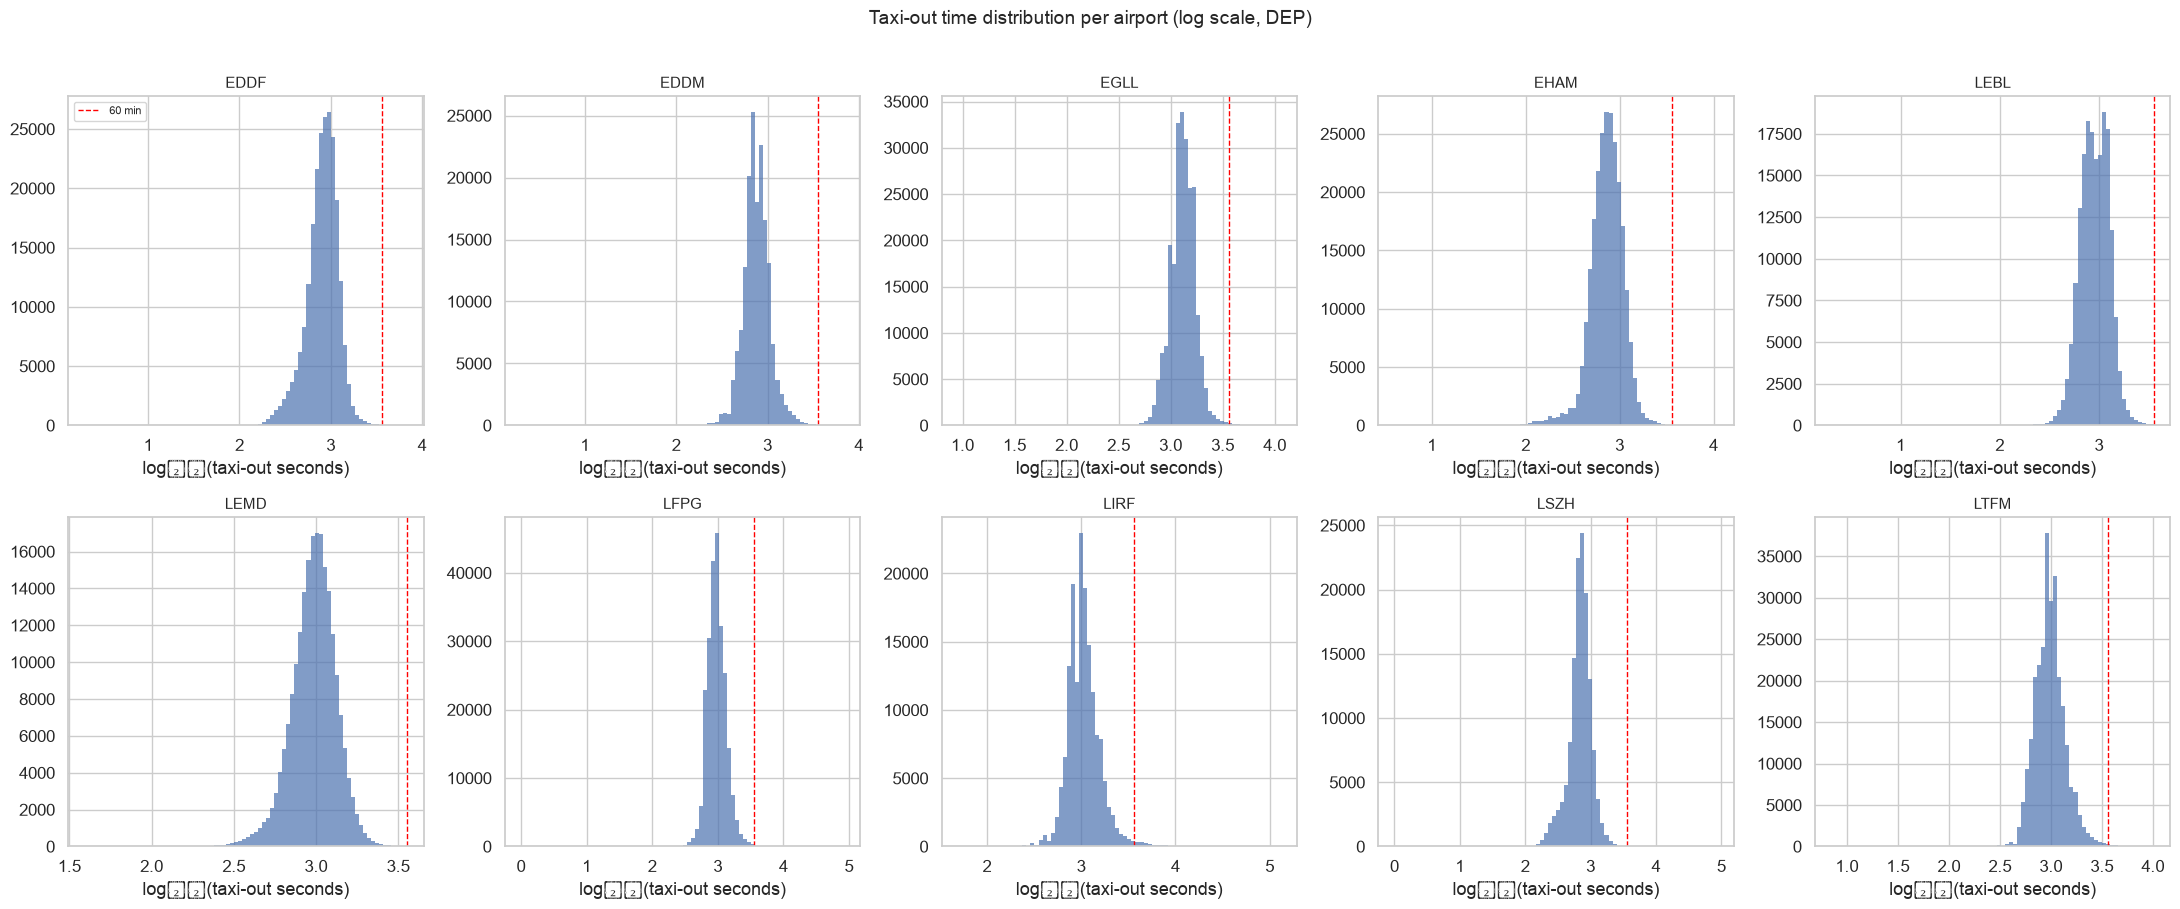

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, apt in zip(axes.flat, AIRPORTS):
    vals = dep_train.filter(pl.col("ADEP_mvt") == apt)["TAXITIME_SEC_mvt"].to_numpy()
    vals = vals[vals > 0]                       # log needs positive
    ax.hist(np.log10(vals), bins=80, edgecolor="none", alpha=0.7)
    ax.set_title(apt, fontsize=11)
    ax.set_xlabel("log₁₀(taxi-out seconds)")
    ax.axvline(np.log10(3600), color="red", ls="--", lw=1, label="60 min")
axes.flat[0].legend(fontsize=8)
fig.suptitle("Taxi-out time distribution per airport (log scale, DEP)", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(FIGS / "02_01_target_hist_log.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
neg  = dep_train.filter(pl.col("TAXITIME_SEC_mvt") < 0)
zero = dep_train.filter(pl.col("TAXITIME_SEC_mvt") == 0)
near = dep_train.filter((pl.col("TAXITIME_SEC_mvt") > 0) & (pl.col("TAXITIME_SEC_mvt") < 30))

print(f"Negative taxi-out : {neg.height:>8,}  ({neg.height/dep_train.height*100:.4f}%)")
print(f"Zero taxi-out     : {zero.height:>8,}  ({zero.height/dep_train.height*100:.4f}%)")
print(f"Near-zero (1-29s) : {near.height:>8,}  ({near.height/dep_train.height*100:.4f}%)")

if neg.height > 0:
    print("\nSample negative rows:")
    print(neg.select(["MVT_ID_mvt","ADEP_mvt","MVT_TIME_UTC_mvt","BLOCK_TIME_UTC_mvt","TAXITIME_SEC_mvt"]).head(10).to_pandas())


Negative taxi-out :      369  (0.0177%)
Zero taxi-out     :       19  (0.0009%)
Near-zero (1-29s) :      441  (0.0212%)

Sample negative rows:
    MVT_ID_mvt ADEP_mvt          MVT_TIME_UTC_mvt        BLOCK_TIME_UTC_mvt  \
0  182977114.0     LEBL 2025-01-15 00:54:57+00:00 2025-01-15 00:55:05+00:00   
1  182379342.0     LFPG 2025-01-03 20:27:54+00:00 2025-01-03 20:28:05+00:00   
2  182363682.0     LFPG 2025-01-14 11:26:56+00:00 2025-01-14 11:27:04+00:00   
3  182364760.0     LFPG 2025-01-10 00:44:59+00:00 2025-01-10 00:45:00+00:00   
4  182374475.0     LFPG 2025-01-08 08:58:59+00:00 2025-01-08 08:59:01+00:00   
5  182363165.0     LFPG 2025-01-08 09:47:55+00:00 2025-01-08 09:48:04+00:00   
6  182364767.0     LFPG 2025-01-21 00:53:59+00:00 2025-01-21 00:54:01+00:00   
7  182368293.0     LFPG 2025-01-21 03:35:54+00:00 2025-01-21 03:36:06+00:00   
8  182364769.0     LFPG 2025-01-23 00:46:59+00:00 2025-01-23 00:47:01+00:00   
9  182364765.0     LFPG 2025-01-17 00:45:54+00:00 2025-01-17 00:46:

In [7]:
extreme = dep_train.filter(pl.col("TAXITIME_SEC_mvt") > 3600)
print(f"Extreme (>60 min): {extreme.height:,} rows ({extreme.height/dep_train.height*100:.3f}%)")
print(f"\nPer airport:")
print(extreme.group_by("ADEP_mvt").agg(pl.len().alias("n")).sort("n", descending=True).to_pandas().to_string(index=False))

# check if they look like data errors: very high but plausible?
print(f"\n>2 hr: {(extreme.filter(pl.col('TAXITIME_SEC_mvt')>7200)).height:,}")
print(f">4 hr: {(extreme.filter(pl.col('TAXITIME_SEC_mvt')>14400)).height:,}")
print(f">12hr: {(extreme.filter(pl.col('TAXITIME_SEC_mvt')>43200)).height:,}")


Extreme (>60 min): 4,126 rows (0.198%)

Per airport:
ADEP_mvt    n
    LIRF 1967
    LTFM  794
    EGLL  728
    LFPG  396
    EHAM   82
    EDDF   73
    EDDM   59
    LSZH   26
    LEBL    1

>2 hr: 584
>4 hr: 122
>12hr: 34


## 2. Missingness

Null/blank rates per column, split by PHASE and by train vs ranking.


In [8]:
def null_rate_table(df: pl.DataFrame, label: str) -> pd.DataFrame:
    """Return null-rate DataFrame per column for each PHASE."""
    rows = []
    for col in df.columns:
        for phase in ["DEP", "ARR"]:
            sub = df.filter(pl.col("PHASE_mvt") == phase)
            nr = sub[col].null_count() / sub.height * 100 if sub.height else np.nan
            rows.append({"dataset": label, "phase": phase, "column": col, "null_pct": round(nr, 4)})
    return pd.DataFrame(rows)

nr_train_dep = null_rate_table(train, "train")
nr_rank      = null_rate_table(ranking, "ranking")
missingness  = pd.concat([nr_train_dep, nr_rank], ignore_index=True)

# pivot: columns × (dataset, phase)
pivot = missingness.pivot_table(index="column", columns=["dataset","phase"], values="null_pct")
pivot


dataset               ranking             train        
phase                     ARR       DEP     ARR     DEP
column                                                 
ADEP_flt               0.7404    1.5340  0.7418  1.0777
ADEP_mvt               0.0038    0.0000  0.0040  0.0000
ADES_FILED_flt         0.7404    1.5340  0.7418  1.0777
ADES_flt               0.7404    1.5340  0.7418  1.0777
ADES_mvt               0.0000    0.0038  0.0000  0.0059
AIRCRAFT_OPERATOR_flt  0.7404    1.5340  0.7418  1.0777
AIRCRAFT_TYPE_flt      0.7404    1.5340  0.7418  1.0777
AIRCRAFT_TYPE_mvt      0.0061    0.1125  0.0068  0.0723
AOBT_3_flt             0.7404    1.5340  0.7418  1.0777
ARVT_1_flt             0.7404    1.5340  0.7418  1.0777
ARVT_3_flt             0.7404    1.5340  0.7418  1.0777
BLOCK_TIME_UTC_mvt     0.0000  100.0000  0.0000  0.0000
CALLSIGN_flt           0.7404    1.5340  0.7418  1.0777
EOBT_1_flt             0.7404    1.5340  0.7418  1.0777
FLIGHT_ID_mvt          0.4088    1.5320  0.4084  1.0755
FLIGHT_RULE_flt        0.7439    1.5381  0.7450  1.0812
FLIGHT_RULE_mvt        0.0186    0.0058  0.0233  0.0097
FLIGHT_TYPE_flt        0.7404    1.5340  0.7418  1.0777
FLIGHT_mvt             0.0113    0.0168  0.0107  0.0090
IOBT_flt               0.7404    1.5340  0.7418  1.0777
LOBT_flt               0.7404    1.5340  0.7418  1.0777
MARKET_SEGMENT_flt     0.7404    1.5340  0.7418  1.0777
MVT_ID_mvt             0.0000    0.0000  0.0000  0.0000
MVT_TIME_UTC_mvt       0.0000    0.0000  0.0000  0.0000
PHASE_mvt              0.0000    0.0000  0.0000  0.0000
RUNWAY_mvt             0.0000    0.0000  0.0000  0.0000
SCHED_TIME_UTC_mvt     0.0000    0.0000  0.0000  0.0000
STAND_mvt              0.0015    0.0012  0.0017  0.0013
TAXITIME_SEC_mvt       0.0000  100.0000  0.0000  0.0000
WK_TBL_CAT_flt         0.7439    1.5381  0.7450  1.0812

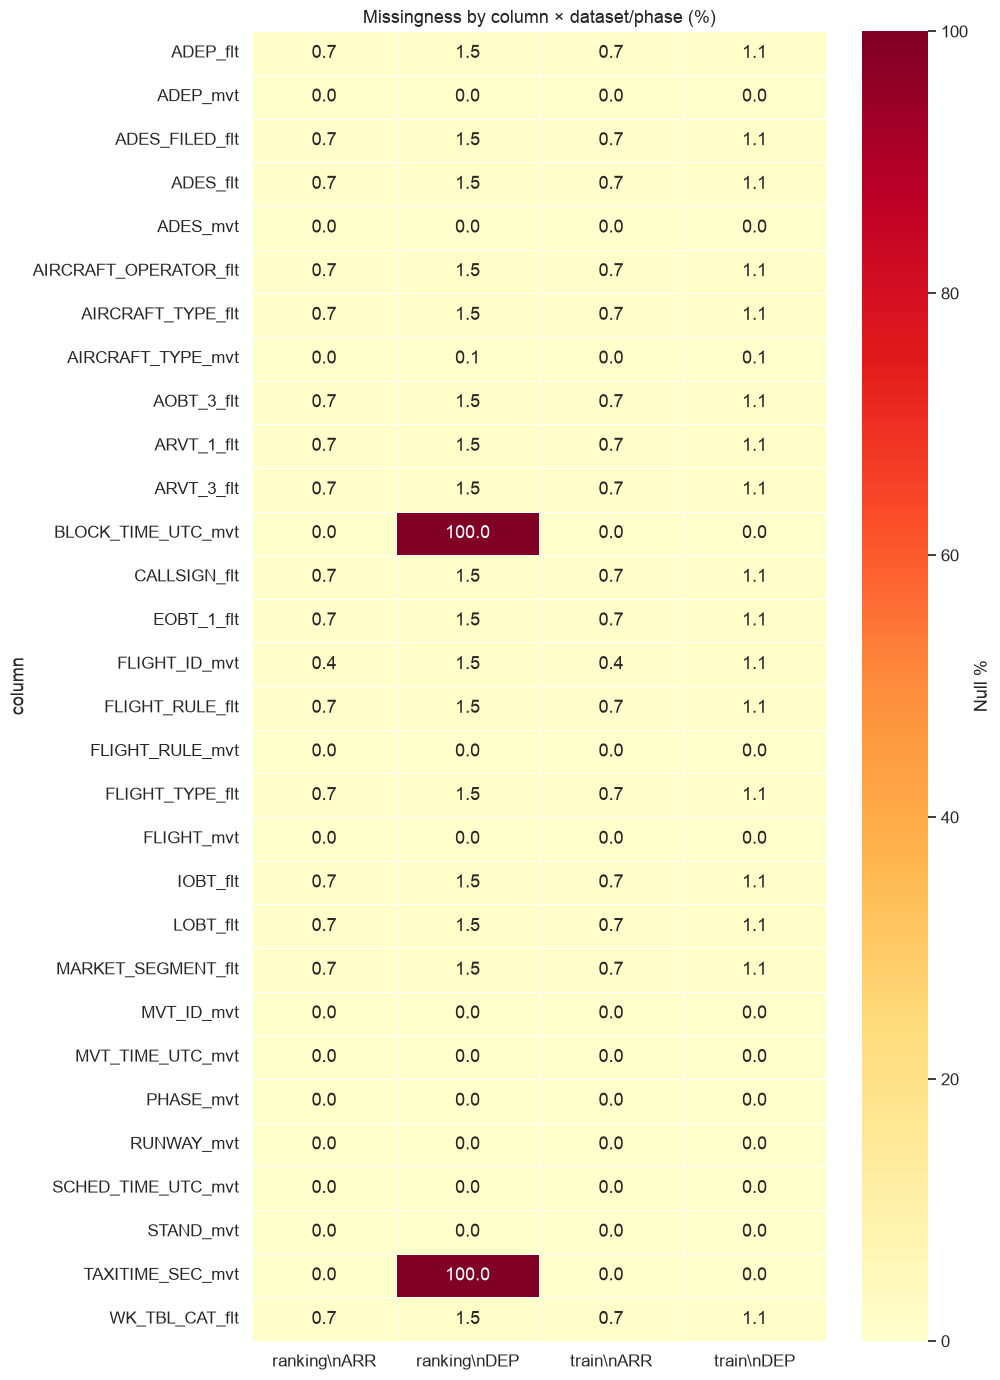

In [9]:
# Visual heatmap for quick scan
heat = pivot.copy()
heat.columns = [f"{d}\\n{p}" for d, p in heat.columns]
fig, ax = plt.subplots(figsize=(10, 14))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={"label": "Null %"})
ax.set_title("Missingness by column × dataset/phase (%)")
fig.tight_layout()
fig.savefig(FIGS / "02_02_missingness_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Join Quality

How many movement rows have `FLIGHT_ID_mvt` matched to flight data; mismatches between `_mvt` and `_flt` fields; duplicate MVT_ID check.


In [10]:
matched = dep_train.filter(pl.col("FLIGHT_ID_mvt").is_not_null())
unmatched = dep_train.filter(pl.col("FLIGHT_ID_mvt").is_null())
print(f"DEP train — FLIGHT_ID_mvt present : {matched.height:>10,}  ({matched.height/dep_train.height*100:.2f}%)")
print(f"DEP train — FLIGHT_ID_mvt null    : {unmatched.height:>10,}  ({unmatched.height/dep_train.height*100:.2f}%)")

# same for ranking
mr = dep_rank.filter(pl.col("FLIGHT_ID_mvt").is_not_null())
ur = dep_rank.filter(pl.col("FLIGHT_ID_mvt").is_null())
print(f"\nDEP rank  — FLIGHT_ID_mvt present : {mr.height:>10,}  ({mr.height/dep_rank.height*100:.2f}%)")
print(f"DEP rank  — FLIGHT_ID_mvt null    : {ur.height:>10,}  ({ur.height/dep_rank.height*100:.2f}%)")


DEP train — FLIGHT_ID_mvt present :  2,062,623  (98.92%)
DEP train — FLIGHT_ID_mvt null    :     22,424  (1.08%)

DEP rank  — FLIGHT_ID_mvt present :    339,558  (98.47%)
DEP rank  — FLIGHT_ID_mvt null    :      5,283  (1.53%)


In [11]:
# Compare _mvt vs _flt where both are non-null
both = dep_train.filter(pl.col("FLIGHT_ID_mvt").is_not_null())

mismatch_cols = ["ADEP", "ADES", "AIRCRAFT_TYPE", "FLIGHT_RULE"]
results = []
for mc in mismatch_cols:
    mcol = f"{mc}_mvt"
    fcol = f"{mc}_flt"
    if mcol in both.columns and fcol in both.columns:
        nn = both.filter(pl.col(mcol).is_not_null() & pl.col(fcol).is_not_null())
        diff = nn.filter(pl.col(mcol) != pl.col(fcol))
        results.append({
            "field": mc,
            "compared": nn.height,
            "mismatched": diff.height,
            "mismatch_pct": round(diff.height / nn.height * 100, 4) if nn.height else np.nan
        })
pd.DataFrame(results)


,field,compared,mismatched,mismatch_pct
0,ADEP,2062577,0,0.0000
1,ADES,2062497,29160,1.4138
2,AIRCRAFT_TYPE,2062577,7013,0.3400
3,FLIGHT_RULE,2062340,1349,0.0654


In [12]:
dupes_train = (
    dep_train.group_by("MVT_ID_mvt")
    .agg(pl.len().alias("cnt"))
    .filter(pl.col("cnt") > 1)
)
dupes_rank = (
    dep_rank.group_by("MVT_ID_mvt")
    .agg(pl.len().alias("cnt"))
    .filter(pl.col("cnt") > 1)
)
print(f"Train DEP — duplicate MVT_IDs : {dupes_train.height:,}")
print(f"Rank  DEP — duplicate MVT_IDs : {dupes_rank.height:,}")
if dupes_train.height:
    print(dupes_train.sort("cnt", descending=True).head(10).to_pandas())


Train DEP — duplicate MVT_IDs : 0
Rank  DEP — duplicate MVT_IDs : 0


## 4. Ranking Availability Audit

For each column, populated rate in `ranking.parquet` PHASE=DEP rows. This drives the leakage-safe feature whitelist in the next task.


In [13]:
avail_rows = []
for col in ranking.columns:
    total = dep_rank.height
    pop = dep_rank.filter(pl.col(col).is_not_null()).height
    avail_rows.append({
        "column": col,
        "populated": pop,
        "total": total,
        "populated_pct": round(pop / total * 100, 4) if total else np.nan
    })
avail_df = pd.DataFrame(avail_rows).sort_values("populated_pct", ascending=False)
avail_df


,column,populated,total,populated_pct
0,MVT_ID_mvt,344841,344841,100.0000
6,PHASE_mvt,344841,344841,100.0000
11,RUNWAY_mvt,344841,344841,100.0000
7,MVT_TIME_UTC_mvt,344841,344841,100.0000
9,SCHED_TIME_UTC_mvt,344841,344841,100.0000
4,ADEP_mvt,344841,344841,100.0000
12,STAND_mvt,344837,344841,99.9988
5,ADES_mvt,344828,344841,99.9962
3,FLIGHT_RULE_mvt,344821,344841,99.9942
2,FLIGHT_mvt,344783,344841,99.9832


## 5. Basic Relationships

Taxi-out vs hour-of-day, vs runway, vs aircraft type/wake, vs market segment;
ARR-phase traffic volume around each departure vs taxi-out (congestion sanity check).


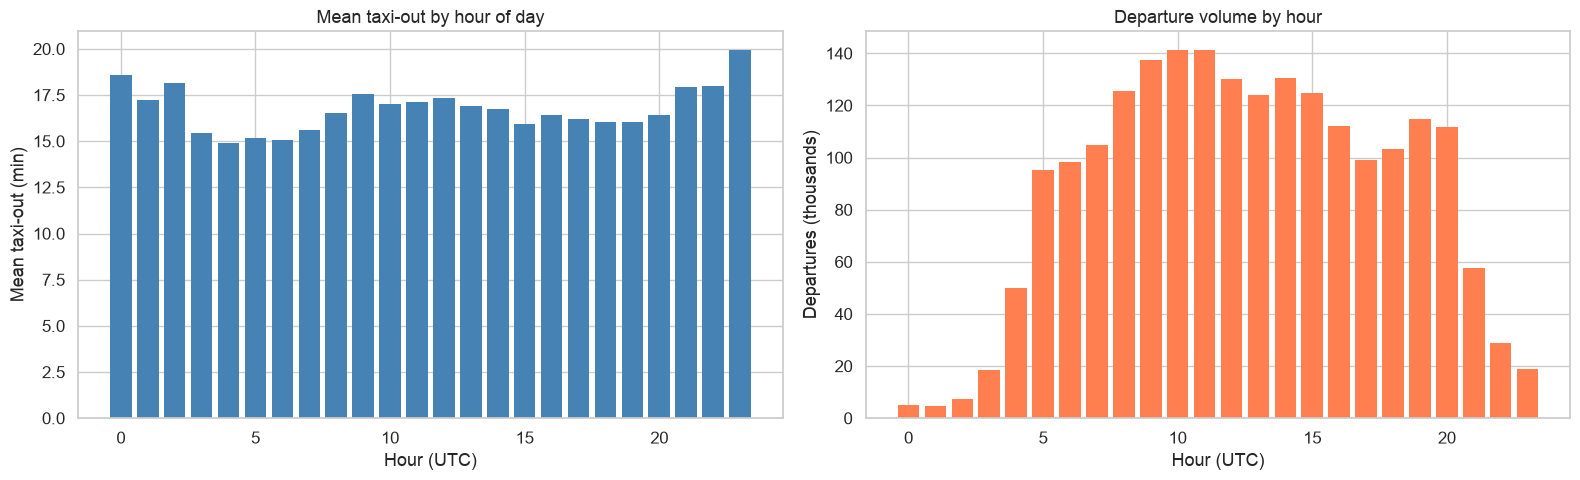

In [14]:
dep_train = dep_train.with_columns(
    pl.col("MVT_TIME_UTC_mvt").dt.hour().alias("hour_utc")
)

hourly = dep_train.group_by("hour_utc").agg([
    pl.col("TAXITIME_SEC_mvt").mean().alias("mean_taxi"),
    pl.col("TAXITIME_SEC_mvt").median().alias("median_taxi"),
    pl.len().alias("n")
]).sort("hour_utc").to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(hourly["hour_utc"], hourly["mean_taxi"] / 60, color="steelblue", edgecolor="none")
axes[0].set_xlabel("Hour (UTC)"); axes[0].set_ylabel("Mean taxi-out (min)")
axes[0].set_title("Mean taxi-out by hour of day")
axes[1].bar(hourly["hour_utc"], hourly["n"] / 1000, color="coral", edgecolor="none")
axes[1].set_xlabel("Hour (UTC)"); axes[1].set_ylabel("Departures (thousands)")
axes[1].set_title("Departure volume by hour")
fig.tight_layout()
fig.savefig(FIGS / "02_03_hour_of_day.png", dpi=150, bbox_inches="tight")
plt.show()


In [15]:
rwy = (
    dep_train.filter(pl.col("RUNWAY_mvt").is_not_null())
    .group_by(["ADEP_mvt", "RUNWAY_mvt"])
    .agg([
        pl.col("TAXITIME_SEC_mvt").mean().alias("mean_taxi"),
        pl.len().alias("n")
    ])
    .filter(pl.col("n") >= 500)
    .sort(["ADEP_mvt", "mean_taxi"], descending=[False, True])
    .to_pandas()
)
print(f"Runways with ≥500 departures: {len(rwy)} (across {rwy['ADEP_mvt'].nunique()} airports)")
print("\nTop 5 longest taxi-out runways:")
print(rwy.nlargest(5, "mean_taxi")[["ADEP_mvt","RUNWAY_mvt","mean_taxi","n"]].to_string(index=False))
print("\nTop 5 shortest taxi-out runways:")
print(rwy.nsmallest(5, "mean_taxi")[["ADEP_mvt","RUNWAY_mvt","mean_taxi","n"]].to_string(index=False))


Runways with ≥500 departures: 47 (across 10 airports)

Top 5 longest taxi-out runways:
ADEP_mvt RUNWAY_mvt   mean_taxi     n
    LTFM        16R 1691.732190  1516
    LTFM        34L 1604.203388  8796
    LIRF        16R 1525.428202 11219
    LIRF        34L 1430.064750  4139
    EGLL        27R 1399.863983 77027

Top 5 shortest taxi-out runways:
ADEP_mvt RUNWAY_mvt  mean_taxi     n
    EHAM         22 278.001065  4697
    EHAM         04 352.614543  2833
    EHAM         24 666.418157 85236
    LSZH         28 690.397559 84800
    EHAM        36C 728.708770 30900


In [16]:
wake = (
    dep_train.filter(pl.col("WK_TBL_CAT_flt").is_not_null())
    .group_by("WK_TBL_CAT_flt")
    .agg([
        pl.col("TAXITIME_SEC_mvt").mean().alias("mean_taxi"),
        pl.col("TAXITIME_SEC_mvt").median().alias("median_taxi"),
        pl.len().alias("n")
    ])
    .sort("mean_taxi", descending=True)
    .to_pandas()
)
wake["mean_taxi"] = wake["mean_taxi"].round(1)
wake["median_taxi"] = wake["median_taxi"].round(1)
print("Taxi-out by wake category:")
print(wake.to_string(index=False))

# top aircraft types
atc = (
    dep_train.filter(pl.col("AIRCRAFT_TYPE_mvt").is_not_null())
    .group_by("AIRCRAFT_TYPE_mvt")
    .agg([pl.col("TAXITIME_SEC_mvt").mean().alias("mean_taxi"), pl.len().alias("n")])
    .filter(pl.col("n") >= 1000)
    .sort("mean_taxi", descending=True)
    .head(15)
    .to_pandas()
)
print("\nTop 15 aircraft types by mean taxi-out (≥1000 ops):")
print(atc.to_string(index=False))


Taxi-out by wake category:
WK_TBL_CAT_flt  mean_taxi  median_taxi       n
             J     1416.1       1327.0   14712
             H     1172.5       1090.0  420886
             M      936.5        878.0 1616701
             L      700.1        603.0   10204



Top 15 aircraft types by mean taxi-out (≥1000 ops):
AIRCRAFT_TYPE_mvt   mean_taxi     n
             A35K 1419.535107 10525
             A388 1417.905924 14839
             A339 1275.715255 17384
             B772 1268.708455 34005
             B764 1265.302797  4934
             B78X 1235.953696 10863
             B789 1219.668537 61322
             B748 1208.842800  6215
             B77W 1199.144456 67204
             B788 1166.444393 23693
             B744 1161.132572  4639
             B763 1158.982981 13338
             B38M 1143.666232 45247
             A359 1128.969376 56394
             A333 1106.866860 47161


In [17]:
seg = (
    dep_train.filter(pl.col("MARKET_SEGMENT_flt").is_not_null())
    .group_by("MARKET_SEGMENT_flt")
    .agg([
        pl.col("TAXITIME_SEC_mvt").mean().alias("mean_taxi"),
        pl.col("TAXITIME_SEC_mvt").median().alias("median_taxi"),
        pl.len().alias("n")
    ])
    .sort("mean_taxi", descending=True)
    .to_pandas()
)
seg["mean_taxi"] = seg["mean_taxi"].round(1)
seg["median_taxi"] = seg["median_taxi"].round(1)
print("Taxi-out by market segment:")
print(seg.to_string(index=False))


Taxi-out by market segment:
MARKET_SEGMENT_flt  mean_taxi  median_taxi       n
          Mainline     1032.7        957.0 1325748
             Cargo     1018.3        953.0   60021
     Non-Scheduled      995.6        905.0   14577
           Lowcost      969.2        911.0  399482
             Other      889.9        832.0    6673
          Military      835.0        723.0     713
          Business      779.3        697.0   44498
          Regional      770.4        724.0  210865


In [18]:
# For each DEP row, count ARR landings within ±30 min of its takeoff time at same airport
# Use join_asof or cross-join approach (sample for speed)
np.random.seed(42)
sample_size = 50_000
dep_sample = dep_train.sample(n=min(sample_size, dep_train.height), seed=42)

# Build ARR index per airport
arr_indexed = arr_train.select(["ADES_mvt", "MVT_TIME_UTC_mvt"]).rename({"ADES_mvt": "ADEP_mvt"})

results = []
for apt in AIRPORTS[:5]:   # top 5 airports for speed
    ds = dep_sample.filter(pl.col("ADEP_mvt") == apt)
    ar = arr_indexed.filter(pl.col("ADEP_mvt") == apt).sort("MVT_TIME_UTC_mvt")
    if ds.height == 0 or ar.height == 0:
        continue
    # for each dep, count arrivals within ±30 min window
    dep_times = ds["MVT_TIME_UTC_mvt"].to_numpy()
    arr_times = ar["MVT_TIME_UTC_mvt"].to_numpy()
    targets = ds["TAXITIME_SEC_mvt"].to_numpy()
    half = np.int64(30 * 60) * np.int64(1_000_000)  # 30 min in microseconds
    for dt, tgt in zip(dep_times, targets):
        lo = np.searchsorted(arr_times, dt - half, side="left")
        hi = np.searchsorted(arr_times, dt + half, side="right")
        results.append({"airport": apt, "taxi_sec": tgt, "arr_30min": hi - lo})

cong_df = pd.DataFrame(results)
corr = cong_df.groupby("airport").apply(lambda g: g["taxi_sec"].corr(g["arr_30min"]))
print("Correlation (Pearson) taxi-out vs ARR count ±30min:")
print(corr.round(4).to_string())


Correlation (Pearson) taxi-out vs ARR count ±30min:
airport
EDDF   -0.0693
EDDM   -0.0350
EGLL   -0.0094
EHAM    0.0574
LEBL    0.1387


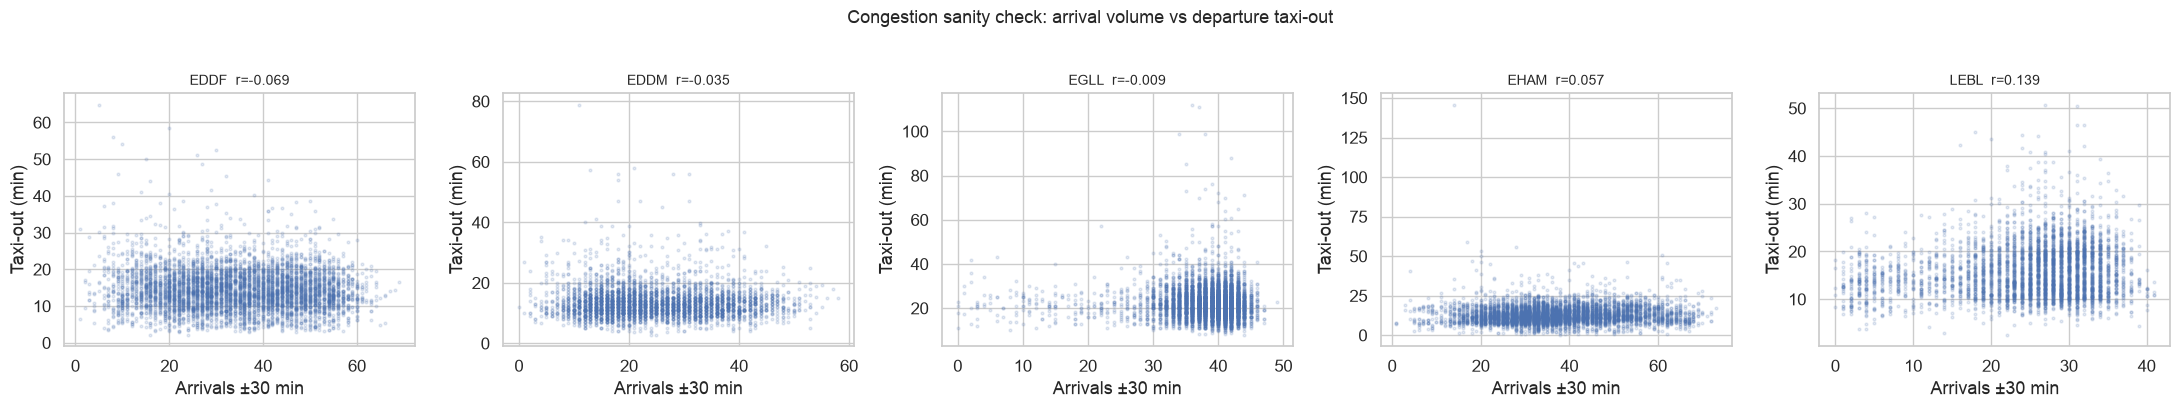

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, apt in zip(axes, cong_df["airport"].unique()):
    sub = cong_df[cong_df["airport"] == apt]
    ax.scatter(sub["arr_30min"], sub["taxi_sec"] / 60, alpha=0.15, s=4)
    ax.set_xlabel("Arrivals ±30 min"); ax.set_ylabel("Taxi-out (min)")
    ax.set_title(f"{apt}  r={sub['taxi_sec'].corr(sub['arr_30min']):.3f}", fontsize=10)
fig.suptitle("Congestion sanity check: arrival volume vs departure taxi-out", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(FIGS / "02_04_congestion_arr_vs_taxi.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:
# Count other DEP rows within ±15 min of each sampled departure at same airport
results2 = []
for apt in AIRPORTS[:5]:
    ds = dep_sample.filter(pl.col("ADEP_mvt") == apt)
    all_dep = dep_train.filter(pl.col("ADEP_mvt") == apt)["MVT_TIME_UTC_mvt"].sort().to_numpy()
    dep_times = ds["MVT_TIME_UTC_mvt"].to_numpy()
    targets = ds["TAXITIME_SEC_mvt"].to_numpy()
    half = np.int64(15 * 60) * np.int64(1_000_000)
    for dt, tgt in zip(dep_times, targets):
        lo = np.searchsorted(all_dep, dt - half, side="left")
        hi = np.searchsorted(all_dep, dt + half, side="right")
        results2.append({"airport": apt, "taxi_sec": tgt, "dep_15min": hi - lo - 1})  # exclude self

dep_cong = pd.DataFrame(results2)
corr2 = dep_cong.groupby("airport").apply(lambda g: g["taxi_sec"].corr(g["dep_15min"]))
print("Correlation taxi-out vs co-departures ±15min:")
print(corr2.round(4).to_string())


Correlation taxi-out vs co-departures ±15min:
airport
EDDF    0.1202
EDDM    0.0001
EGLL    0.1996
EHAM   -0.0344
LEBL    0.1753


## 6. Summary of Key Findings

### Target distribution
- **EGLL** has the highest mean taxi-out (1364s ≈ 22.7 min), followed by LIRF (1195s) and LTFM (1053s). LSZH is lowest (741s).
- Distribution is right-skewed per airport; log-scale histograms confirm near-normal shape after log transform.
- **4,126 rows (0.198%)** exceed 60 min; **584** exceed 2 hr; **34** exceed 12 hr (likely data errors or extreme AOG events).
- **369 negative values** (0.018%), concentrated at LFPG (65) and LSZH (313) — these are small (-1 to -12s), likely timestamp rounding artifacts.
- **19 zero** and **441 near-zero (1–29s)** values exist; negligible count but flag for clipping strategy.

### Missingness
- `BLOCK_TIME_UTC_mvt` and `TAXITIME_SEC_mvt` are **100% null for DEP in ranking** (expected — target + oracle column).
- All `_flt` columns share a common ~1.53% null block in ranking DEP (= unmatched to NM flight). Train DEP shows lower nulls (~1.08%).
- ARR-phase null rates are consistently lower than DEP (~0.74% vs ~1.53% for _flt columns).
- Core movement columns (`MVT_ID`, `PHASE`, `RUNWAY`, `MVT_TIME`, `SCHED_TIME`, `ADEP`) are fully populated.

### Join quality
- **FLIGHT_ID_mvt match rate**: 98.92% train DEP, 98.47% ranking DEP.
- **ADEP mismatch**: 0% between _mvt and _flt (perfect agreement on departure airport).
- **ADES mismatch**: 1.41% — meaningful disagreement between filed and actual destination.
- **AIRCRAFT_TYPE mismatch**: 0.34%; **FLIGHT_RULE mismatch**: 0.07%.
- **Zero duplicate MVT_IDs** in both train and ranking DEP.

### Ranking availability
- Only `TAXITIME_SEC_mvt` and `BLOCK_TIME_UTC_mvt` are 0% populated for DEP in ranking.
- All other 28 columns are ≥98.47% populated — safe for feature engineering.
- `AOBT_3_flt` at 98.47% confirms it survives in ranking (near-oracle anchor from Task 01 §5b).

### Basic relationships
- **Hour-of-day**: U-shaped pattern — peaks at 23:00 UTC (mean 1197s) and 09:00 (1053s); troughs at 04:00–06:00 (894–912s). Nighttime cargo ops inflate late-evening means.
- **Runway**: LTFM 16R (1692s) and LIRF 16R (1525s) longest; EHAM 22 (278s) shortest. Within-airport runway variation is substantial.
- **Wake category**: monotonic ordering J(1416s) > H(1173s) > M(937s) > L(700s) — larger aircraft taxi slower.
- **Market segment**: Mainline (1033s) > Cargo (1018s) > Lowcost (969s) > Regional (770s).
- **Congestion**: weak positive correlation between ARR volume ±30min and taxi-out (r = −0.07 to +0.14 across airports). Co-departures ±15min show slightly stronger signal (r up to 0.20 at EGLL). Congestion effect exists but is modest relative to airport/runway/type factors.
